In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
BASE  = '/content/drive/MyDrive/capcapstone/dr_detection'
CLEAN = f'{BASE}/clean_data'
OUT   = f'{BASE}/outputs'
sys.path.insert(0, f'{BASE}/raw_data')

# Can we write to the shared outputs folder?
try:
    t = f'{OUT}/_write_test.tmp'
    open(t, 'w').write('x'); os.remove(t)
    SAVE_DIR, NEED_DOWNLOAD = OUT, False
    print('✅ outputs folder is writable')
except Exception:
    SAVE_DIR, NEED_DOWNLOAD = '/content', True
    print('⚠️ outputs not writable: files will save to /content and download')

for p in ['raw_data/model.py', 'best_model.pth',
          'clean_data/test/labels.csv', 'outputs/metrics_log.csv']:
    print('✅' if os.path.exists(f'{BASE}/{p}') else '❌', p)

Mounted at /content/drive
✅ outputs folder is writable
✅ raw_data/model.py
✅ best_model.pth
✅ clean_data/test/labels.csv
✅ outputs/metrics_log.csv


In [2]:
!pip install timm -q

import torch, numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as transforms
from model import HybridDRModel

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

model = HybridDRModel().to(device)
state = torch.load(f'{BASE}/best_model.pth', map_location=device)
if isinstance(state, dict) and 'state_dict' in state: state = state['state_dict']
state = {k.replace('module.', ''): v for k, v in state.items()}
print(model.load_state_dict(state, strict=False))   # should say <All keys matched successfully>
model.eval()

# Force manual attention so we can read attention maps
for blk in model.vit.blocks:
    if hasattr(blk.attn, 'fused_attn'): blk.attn.fused_attn = False

print('ViT blocks:', len(model.vit.blocks))

model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

device: cuda
<All keys matched successfully>
ViT blocks: 12


['epoch', 'train_loss', 'val_loss', 'acc', 'f1', 'qwk', 'auc'] | 31 epochs


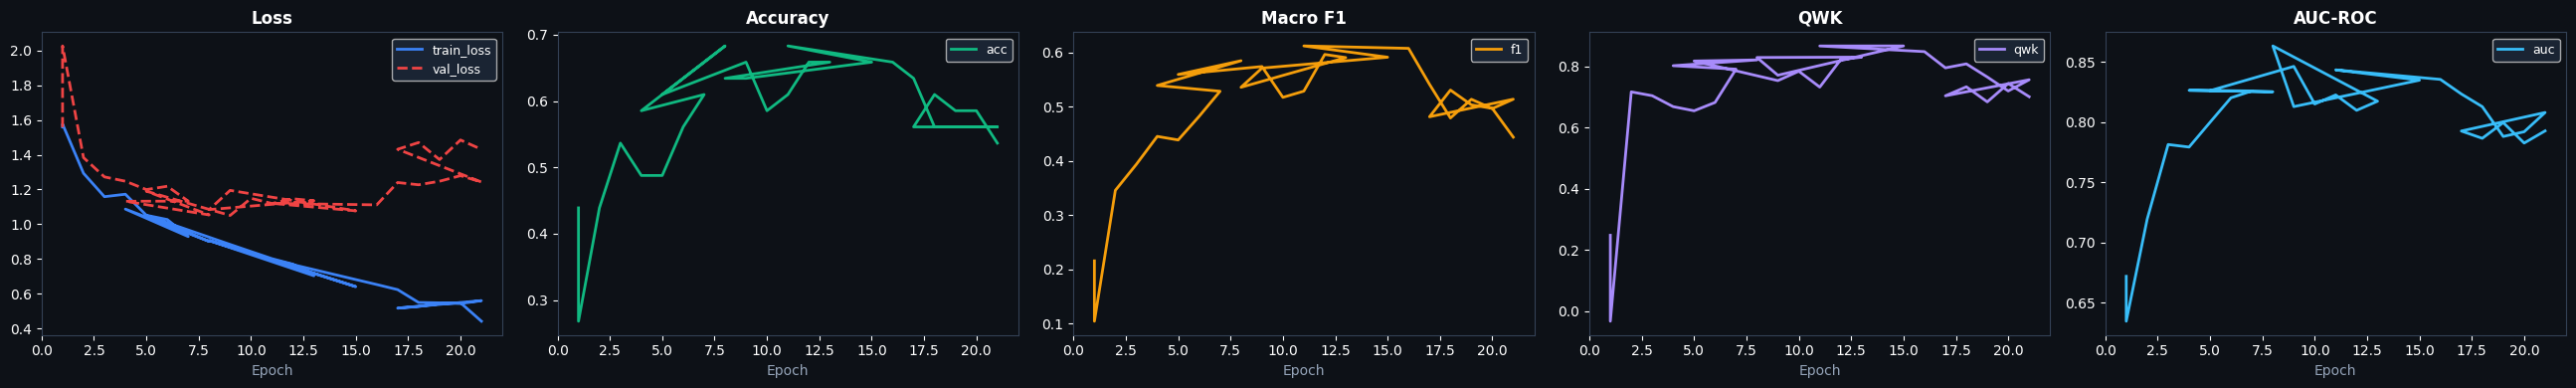

✅ saved training_curves_v2.png


In [3]:
log = pd.read_csv(f'{OUT}/metrics_log.csv')
print(log.columns.tolist(), '|', len(log), 'epochs')

specs = [('train_loss','val_loss','Loss','#3b82f6','#ef4444'),
         ('acc',None,'Accuracy','#10b981',None),
         ('f1',None,'Macro F1','#f59e0b',None),
         ('qwk',None,'QWK','#a78bfa',None),
         ('auc',None,'AUC-ROC','#38bdf8',None)]
specs = [s for s in specs if s[0] in log.columns]

fig, axes = plt.subplots(1, len(specs), figsize=(5.2*len(specs), 4), facecolor='#0d1117')
for ax, (m1, m2, title, c1, c2) in zip(np.atleast_1d(axes), specs):
    ax.set_facecolor('#0d1117')
    ax.plot(log.epoch, log[m1], color=c1, lw=2, label=m1)
    if m2 and m2 in log.columns:
        ax.plot(log.epoch, log[m2], color=c2, lw=2, ls='--', label=m2)
    ax.set_title(title, color='white', fontweight='bold')
    ax.set_xlabel('Epoch', color='#94a3b8')
    ax.tick_params(colors='white')
    ax.legend(facecolor='#1e293b', labelcolor='white', fontsize=9)
    for sp in ax.spines.values(): sp.set_edgecolor('#334155')
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/training_curves_v2.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('✅ saved training_curves_v2.png')

In [4]:
TRANSFORM = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225]),
])

def attention_rollout(model, tensor):
    """Rollout across all ViT blocks. Returns a 14x14 map in [0,1]."""
    store, originals = [], []
    for blk in model.vit.blocks:
        m = blk.attn
        originals.append(m.forward)
        def make(m):
            def patched(x, *a, **k):
                B, N, C = x.shape
                qkv = m.qkv(x).reshape(B, N, 3, m.num_heads, C // m.num_heads).permute(2,0,3,1,4)
                q, kk, v = qkv.unbind(0)
                attn = ((q @ kk.transpose(-2,-1)) * m.scale).softmax(dim=-1)
                store.append(attn.detach().cpu())
                out = (attn @ v).transpose(1,2).reshape(B, N, C)
                return m.proj_drop(m.proj(out))
            return patched
        m.forward = make(m)

    try:
        with torch.no_grad():
            model(tensor)
    finally:
        for blk, orig in zip(model.vit.blocks, originals):
            blk.attn.forward = orig

    result = None
    for a in store:
        a = a[0].mean(0)
        a = a + torch.eye(a.size(0))
        a = a / a.sum(dim=-1, keepdim=True)
        result = a if result is None else a @ result

    cls = result[0, 1:]
    g = int(cls.numel() ** 0.5)
    mp = cls.reshape(g, g).numpy()
    return (mp - mp.min()) / (mp.max() - mp.min() + 1e-8)

# quick test
test_df = pd.read_csv(f'{CLEAN}/test/labels.csv')
print(test_df.head(3)); print(test_df.columns.tolist())

             image_path  grade                mask_path  brightness  contrast
0  images/IDRiD_331.png      0  test/IDRiD_331_mask.npy   -1.163086  1.030320
1  images/IDRiD_098.png      3  test/IDRiD_098_mask.npy   -1.306582  1.053710
2  images/IDRiD_057.png      3  test/IDRiD_057_mask.npy   -1.097344  1.061893
['image_path', 'grade', 'mask_path', 'brightness', 'contrast']


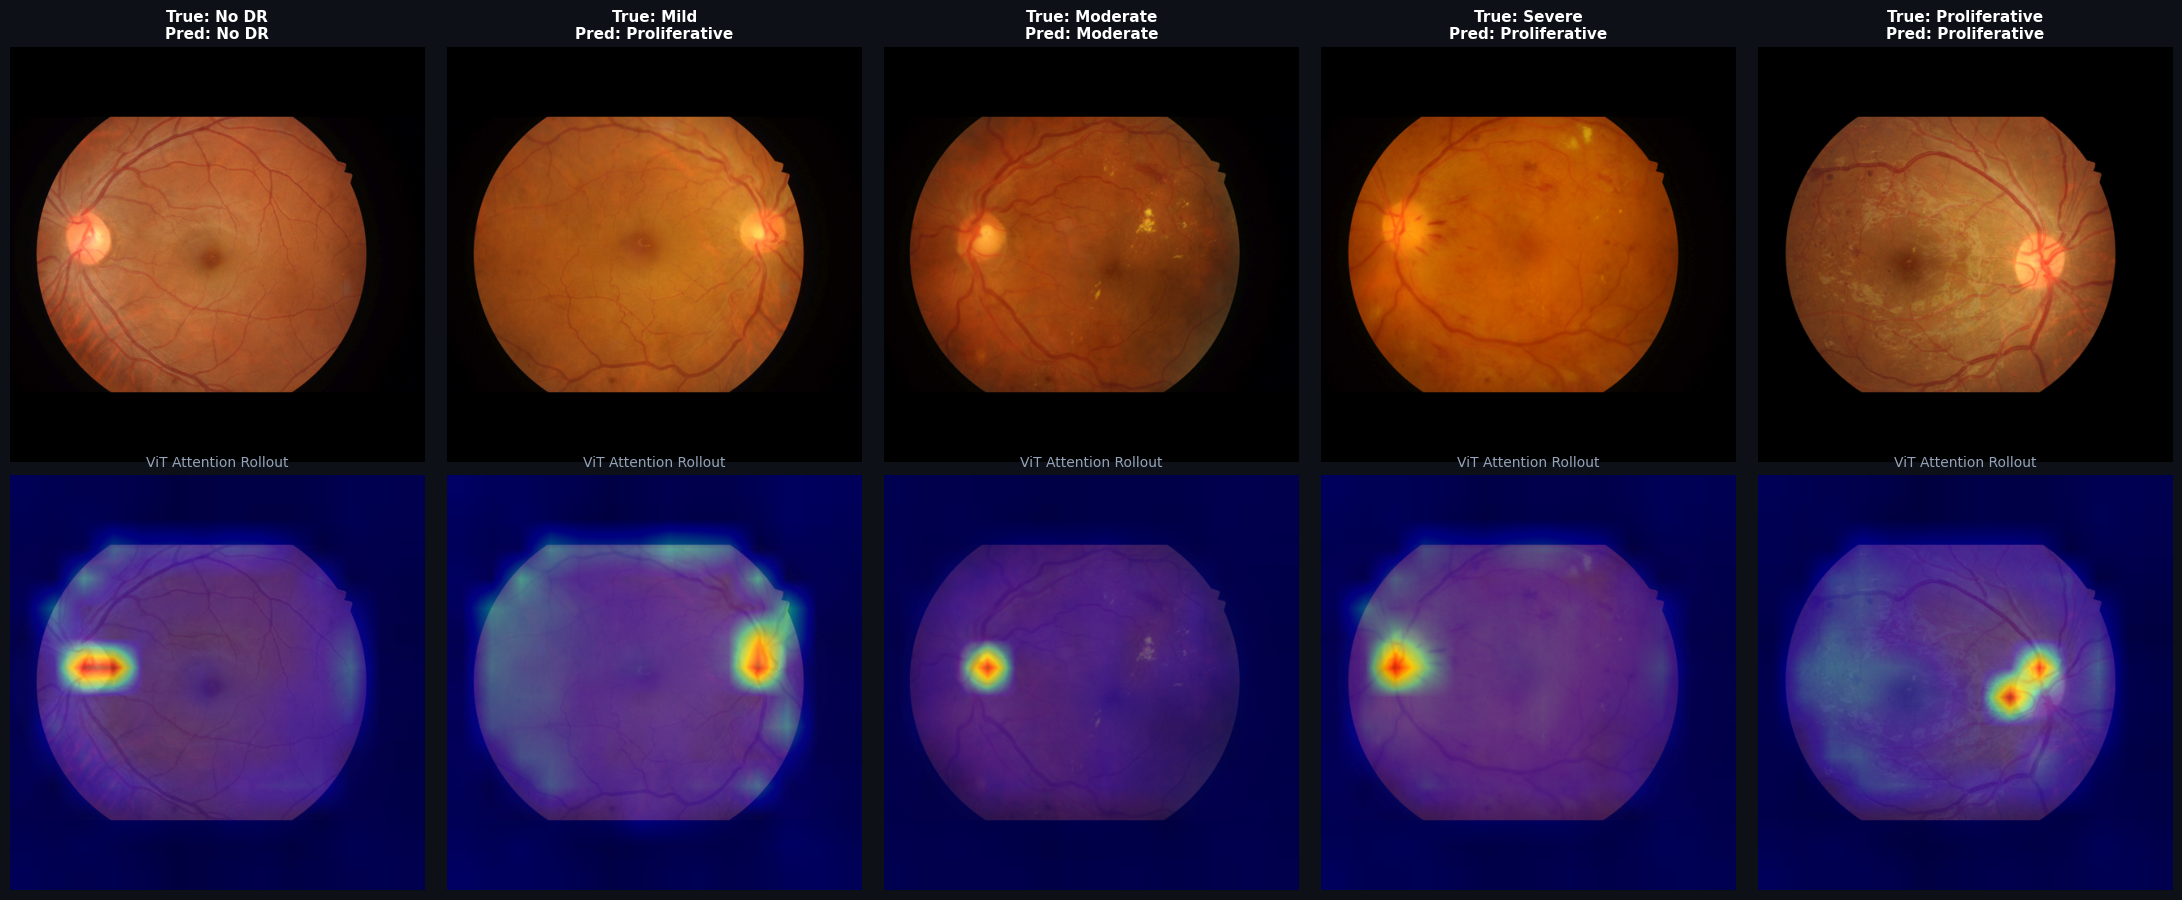

✅ saved attention_gallery.png


In [5]:
GRADE_NAMES = ['No DR','Mild','Moderate','Severe','Proliferative']

def find_img(p):
    for c in [f'{CLEAN}/{p}', f'{CLEAN}/test/{p}', os.path.normpath(f'{CLEAN}/test/{p}')]:
        if os.path.exists(c): return c
    raise FileNotFoundError(p)

fig, axes = plt.subplots(2, 5, figsize=(22, 9), facecolor='#0d1117')
for g in range(5):
    sub = test_df[test_df.grade == g]
    if len(sub) == 0:
        axes[0][g].axis('off'); axes[1][g].axis('off'); continue
    row = sub.iloc[0]
    img = Image.open(find_img(row['image_path'])).convert('RGB')
    tensor = TRANSFORM(img).unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(tensor).argmax(1).item()

    r = attention_rollout(model, tensor)
    r_up = np.array(Image.fromarray((r*255).astype(np.uint8)).resize((512,512), Image.BILINEAR)) / 255.0
    base = np.array(img.resize((512,512)))

    axes[0][g].imshow(base); axes[0][g].axis('off')
    axes[0][g].set_title(f'True: {GRADE_NAMES[g]}\nPred: {GRADE_NAMES[pred]}',
                         color='white', fontsize=11, fontweight='bold')
    axes[1][g].imshow(base); axes[1][g].imshow(r_up, cmap='jet', alpha=0.5); axes[1][g].axis('off')
    axes[1][g].set_title('ViT Attention Rollout', color='#94a3b8', fontsize=10)

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/attention_gallery.png', dpi=130, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('✅ saved attention_gallery.png')

In [6]:
for f in ['training_curves_v2.png', 'attention_gallery.png']:
    p = f'{SAVE_DIR}/{f}'
    print('✅' if os.path.exists(p) else '❌', p)

if NEED_DOWNLOAD:
    from google.colab import files
    for f in ['training_curves_v2.png', 'attention_gallery.png']:
        files.download(f'/content/{f}')
    print('Upload these two files to dr_detection/outputs/ in Drive')

✅ /content/drive/MyDrive/capcapstone/dr_detection/outputs/training_curves_v2.png
✅ /content/drive/MyDrive/capcapstone/dr_detection/outputs/attention_gallery.png
